# 02 · PTF forecasting models

**Goal:** forecast the 24 hourly day-ahead prices (PTF, USD/MWh) of day D+1 on day D, before the 12:30 offer deadline, using only the information available at that moment.

**How to read this notebook.** Each section asks one question, shows the evidence and ends with findings. The code lives in `src/` (reusable functions) and `scripts/` (runs that write `reports/results/`). Long runs (hyperparameter searches, the GRU, the classical time series models) are **not repeated here**: their saved results are read, and every cell names the script that produced them. The quick steps (features, the leakage check, one training run) are run live.

| Period | Dates | Used for |
|---|---|---|
| Training | from 2024-01-01 | fitting the models |
| Validation | 2025, four quarters (walk-forward) | model choice and tuning |
| Test | 2026-01-01 – 2026-09-30 | scored **once**, after the model was fixed |
| Demo | from 2026-10-01 | never used for training or model choice |

**Metric:** mean absolute error (MAE, USD/MWh), the average size of an hourly price error. RMSE and MAE on price-floor and price-cap hours are reported alongside.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))  # notebooks run from notebooks/; make `src` importable

import json
import pandas as pd
from src.config import PROCESSED_DIR, ROOT
from src import plots

pd.set_option('display.width', 200)
pd.set_option('display.precision', 2)
RESULTS = ROOT / 'reports' / 'results'

table = pd.read_parquet(PROCESSED_DIR / 'ptf_hourly.parquet')
flags = table[['is_price_floor', 'is_price_cap']]


def mean_over_folds(results: pd.DataFrame, reference='same hour yesterday') -> pd.DataFrame:
    # MAE per quarter, the mean over the four quarters and the improvement over the reference baseline
    per_fold = results.pivot_table(index='model', columns='fold', values='mae')
    per_fold['mean'] = per_fold.mean(axis=1)
    per_fold['vs_baseline_%'] = 100 * (1 - per_fold['mean'] / per_fold.loc[reference, 'mean'])
    return per_fold.sort_values('mean')

## 3.1 What does the model see?

Every input must be known before 12:30 on day D. Each column of the hourly table carries an availability label (`src/dataset.py`), and each label has a minimum lag in hours (`src/features.py`):

- `known_ahead` (load and wind forecasts, price cap): published for D+1 before the deadline → lag 0
- PTF: day D's prices were published on D-1 at 14:00 → lag ≥ 24 h
- other `past_only` columns (realised generation, consumption, other prices): known up to the end of D-1 → lag ≥ 48 h
- `evaluation_only`: never an input

In [2]:
from src.dataset import COLUMN_AVAILABILITY
from src.features import FEATURE_SPEC, build_features, check_spec, feature_name, min_lag

spec = pd.DataFrame([{'feature': feature_name(c, lag), 'source column': c,
                      'label': COLUMN_AVAILABILITY.get(c, 'derived, known_ahead'),
                      'lag (h)': lag, 'minimum lag (h)': min_lag(c)} for c, lag in FEATURE_SPEC])
spec

,feature,source column,label,lag (h),minimum lag (h)
0,load_forecast,load_forecast,known_ahead,0,0
1,wind_forecast,wind_forecast,known_ahead,0,0
2,net_load_forecast,net_load_forecast,"derived, known_ahead",0,0
3,price_cap_try,price_cap_try,known_ahead,0,0
4,ptf_usd_lag24,ptf_usd,target,24,24
5,ptf_usd_lag48,ptf_usd,target,48,24
6,ptf_usd_lag168,ptf_usd,target,168,24
7,gen_solar_lag48,gen_solar,past_only,48,48
8,gen_solar_lag168,gen_solar,past_only,168,48


`build_features` adds the previous day's mean price and the calendar of the target hour (hour, day of week, weekend, month, official holidays, holiday-eve afternoon). It calls `check_spec` first, so a feature that breaks the rules cannot be built:

In [3]:
X, y = build_features(table)
print(f'{X.shape[1]} inputs, {len(X):,} hours from {X.index[0]:%Y-%m-%d} to {X.index[-1]:%Y-%m-%d}')
print(list(X.columns))

for bad in [('gen_solar', 24), ('ptf_usd', 0)]:   # realised solar of day D; today's price for today
    try:
        check_spec(FEATURE_SPEC + [bad])
    except ValueError as error:
        print('rejected:', error)

16 inputs, 24,888 hours from 2024-01-01 to 2026-11-02
['load_forecast', 'wind_forecast', 'net_load_forecast', 'price_cap_try', 'ptf_usd_lag24', 'ptf_usd_lag48', 'ptf_usd_lag168', 'gen_solar_lag48', 'gen_solar_lag168', 'ptf_usd_prev_day_mean', 'hour', 'day_of_week', 'is_weekend', 'month', 'is_holiday', 'is_holiday_eve_afternoon']
rejected: leakage: 'gen_solar' used with lag 24 h, needs at least 48 h
rejected: leakage: 'ptf_usd' used with lag 0 h, needs at least 24 h


**Findings (3.1)**

1. **16 inputs** in four groups: past prices (same hour yesterday, 2 days ago, last week; yesterday's mean), next-day forecasts (load, wind, net load = load − wind, price cap), past solar generation (2 days ago, last week) and the calendar of the target hour.
2. **Leakage is blocked in code, not by convention.** Using day D's realised solar (lag 24) or the target day's own price (lag 0) raises an error before any feature is built.

## 3.2 What do we have to beat?

Three references that need no model:

- **dummy:** the training median for every hour (a sanity check: a model that does not beat it is broken)
- **same hour last week**
- **same hour yesterday:** the baseline every model has to beat, a forecast anyone has for free

Validation is a quarterly walk-forward over 2025: for each quarter the model is trained on everything from 2024-01-01 to the day before the quarter starts, then scored on that quarter.

*Source: `python -m scripts.compare_models` → `reports/results/model_comparison.csv`*

In [4]:
from src.evaluation import WALK_FORWARD_FOLDS

pd.DataFrame(WALK_FORWARD_FOLDS, columns=['quarter', 'first day', 'last day'])

,quarter,first day,last day
0,2025Q1,2025-01-01,2025-03-31
1,2025Q2,2025-04-01,2025-06-30
2,2025Q3,2025-07-01,2025-09-30
3,2025Q4,2025-10-01,2025-12-31


In [5]:
comparison = pd.read_csv(RESULTS / 'model_comparison.csv')
references = ['dummy (median)', 'same hour last week', 'same hour yesterday']
mean_over_folds(comparison[comparison['model'].isin(references)])

fold,2025Q1,2025Q2,2025Q3,2025Q4,mean,vs_baseline_%
model,,,,,,
same hour yesterday,8.66,14.20,9.12,8.58,10.14,0.00
same hour last week,8.90,15.63,7.37,9.21,10.28,-1.37
dummy (median),12.29,20.33,11.72,11.60,13.98,-37.89


**Findings (3.2)**

1. **The bar: 10.14 USD/MWh** (same hour yesterday, mean over the four quarters). Same hour last week is close (10.28) and better in Q3 (7.37 vs 9.12).
2. **The dummy is far behind (13.98):** yesterday's price already carries most of the information a constant ignores.
3. **2025Q2 is the hardest quarter** for every reference (14.20 for the baseline): spring prices move more from day to day.

## 3.3 Which family of models works?

All models with reasonable starting settings (`src/models.py`), on the same quarters, inputs and metric. One model covers all 24 hours: each row is one target hour, and the hour is an input.

- **ridge:** a linear model; calendar columns one-hot encoded, the rest scaled
- **random forest, HistGradientBoosting, XGBoost:** tree ensembles, which can learn thresholds and interactions (for example hour × net load) on their own

*Source: `python -m scripts.compare_models` → `reports/results/model_comparison.csv`*

In [6]:
mean_over_folds(comparison)

fold,2025Q1,2025Q2,2025Q3,2025Q4,mean,vs_baseline_%
model,,,,,,
hist gradient boosting,7.25,9.26,5.40,6.69,7.15,29.50
xgboost,7.02,9.33,5.50,6.93,7.19,29.06
random forest,6.77,9.82,6.08,6.43,7.27,28.27
ridge,7.90,12.00,7.64,8.33,8.97,11.57
same hour yesterday,8.66,14.20,9.12,8.58,10.14,0.00
same hour last week,8.90,15.63,7.37,9.21,10.28,-1.37
dummy (median),12.29,20.33,11.72,11.60,13.98,-37.89


**One training run, live.** XGBoost with its starting settings on the last quarter (trained on 2024-01-01 – 2025-09-30, scored on 2025Q4). It should reproduce the saved number in the table above.

In [7]:
import time
from src.evaluation import mae, walk_forward_splits
from src.models import fit, predict

fold, X_tr, y_tr, X_val, y_val = list(walk_forward_splits(X, y))[-1]
start = time.time()
model = fit('xgboost', X_tr, y_tr)
live = mae(y_val, predict(model, X_val))
saved = comparison.query("model == 'xgboost' and fold == @fold")['mae'].item()
print(f'{fold}: trained on {len(X_tr):,} hours in {time.time() - start:.1f} s')
print(f'MAE live {live:.3f} | saved {saved:.3f}')

2025Q4: trained on 15,336 hours in 2.6 s
MAE live 6.933 | saved 6.933


**Findings (3.3)**

1. **The three tree ensembles are about 28–30% better than the baseline** (MAE 7.15–7.27) and close to each other. Each wins a different quarter: random forest Q1 and Q4, HistGradientBoosting Q2 and Q3, XGBoost none. With starting settings, none of them is clearly the best.
2. **Ridge beats the baseline by 12% (8.97)** but stays well behind the trees. A linear model cannot learn that the same net load means a different price at noon and in the evening without hand-made interaction terms.
3. **The saved results are reproducible:** the live run gives the same MAE as the saved table.

→ **Decision:** tune all three tree ensembles (3.4) instead of picking one now.

## 3.4 What does tuning add?

Hyperparameter search with Optuna (`src/tuning.py`) on the same four quarters. Each trial: Optuna proposes settings → the model is trained on every quarter → score = mean validation MAE. Its sampler (TPE) learns from earlier trials which settings look promising. A trial that is clearly worse than earlier ones after a quarter is stopped early (*pruned*), which saves time on bad settings. The test period is never involved.

Search budget: XGBoost and HistGradientBoosting 50 trials each, random forest 30 (the slowest to train).

*Source: `python -m scripts.tune_models` → `reports/results/tuning/`*

,trials,completed,pruned,best mean MAE
xgboost,50.0,50.0,0.0,6.88
hist gradient boosting,50.0,37.0,13.0,6.96
random forest,30.0,30.0,0.0,7.12


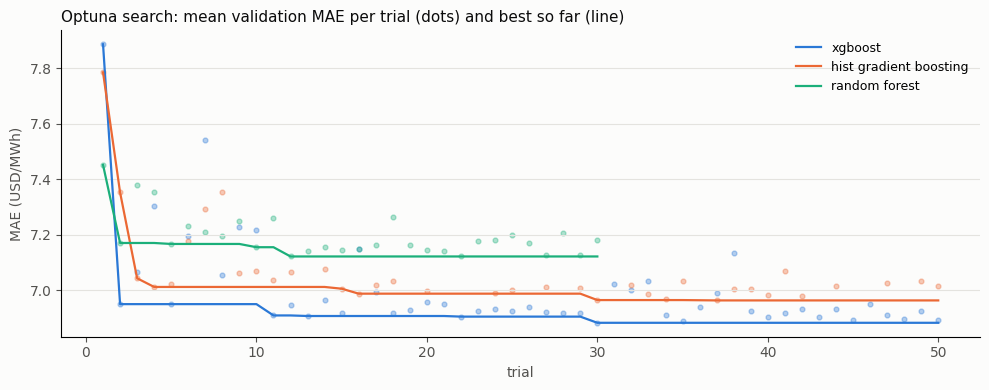

In [8]:
import matplotlib.pyplot as plt

TUNED = ['xgboost', 'hist gradient boosting', 'random forest']
fig, ax = plt.subplots(figsize=(10, 4), facecolor=plots.SURFACE)
search = {}
for name, color in zip(TUNED, [plots.BLUE, plots.ORANGE, plots.AQUA]):
    trials = pd.read_csv(RESULTS / 'tuning' / f"{name.replace(' ', '_')}_trials.csv")
    done = trials[trials['state'] == 'COMPLETE']
    ax.scatter(done['number'] + 1, done['value'], s=12, color=color, alpha=0.35)
    ax.plot(done['number'] + 1, done['value'].cummin(), color=color, linewidth=1.6, label=name)
    search[name] = {'trials': len(trials), 'completed': len(done),
                    'pruned': int((trials['state'] == 'PRUNED').sum()), 'best mean MAE': done['value'].min()}
plots.style(ax, 'Optuna search: mean validation MAE per trial (dots) and best so far (line)',
            ylabel='MAE (USD/MWh)', xlabel='trial')
ax.legend(frameon=False, fontsize=9)
fig.tight_layout()
pd.DataFrame(search).T

In [9]:
tuned = pd.read_csv(RESULTS / 'tuning' / 'tuned_comparison.csv')
default_trees = comparison[comparison['model'].isin(TUNED + ['same hour yesterday'])]
mean_over_folds(pd.concat([default_trees, tuned]))

fold,2025Q1,2025Q2,2025Q3,2025Q4,mean,vs_baseline_%
model,,,,,,
xgboost (tuned),6.76,9.03,5.15,6.60,6.88,32.12
hist gradient boosting (tuned),6.93,9.20,5.16,6.57,6.96,31.32
random forest (tuned),6.46,9.84,5.77,6.43,7.12,29.76
hist gradient boosting,7.25,9.26,5.40,6.69,7.15,29.50
xgboost,7.02,9.33,5.50,6.93,7.19,29.06
random forest,6.77,9.82,6.08,6.43,7.27,28.27
same hour yesterday,8.66,14.20,9.12,8.58,10.14,0.00


In [10]:
best_params = json.loads((RESULTS / 'tuning' / 'best_params.json').read_text())
def show_params(params: dict, name: str) -> pd.DataFrame:
    # 4 significant digits, so small values (learning rate, regularisation) do not show as 0.0
    return pd.Series({k: f'{v:.4g}' if isinstance(v, float) else v for k, v in params.items()}, name=name).to_frame()

show_params(best_params['xgboost'], 'tuned XGBoost')

,tuned XGBoost
n_estimators,441
learning_rate,0.02007
max_depth,7
min_child_weight,16
subsample,0.9063
colsample_bytree,0.661
reg_lambda,0.001272
objective,reg:absoluteerror


**Findings (3.4)**

1. **Tuning helped all three models, by 0.15–0.31 USD/MWh:** XGBoost 7.19 → 6.88, HistGradientBoosting 7.15 → 6.96, random forest 7.27 → 7.12. The gain is real but much smaller than the gap between the trees and ridge (about 2 USD/MWh): the inputs matter more than the settings.
2. **Tuned XGBoost has the lowest mean (6.88), 32% below the baseline,** but the margin is small and it does not win every quarter: it is best in Q2 and Q3, tuned random forest in Q1 and Q4.
3. **Most of the improvement came in the first dozen trials** (chart): after that the best result of each model barely moved, so a larger budget would likely not change the choice.
4. **The search chose `reg:absoluteerror`:** XGBoost minimises the absolute error directly, the same quantity as our metric. A minimum of 16 samples per leaf and 66% of the inputs per tree keep the trees from fitting noise.

→ **Decision: tuned XGBoost** is the chosen model (lowest mean validation MAE, the pre-set criterion).

## 3.5 Where does deep learning stand?

A GRU (`src/sequences.py`, `src/gru.py`) sees the data differently: one sample is one forecast day.

- **past sequence:** the last 168 hours up to D 23:00 (price, net load forecast, realised solar, each only as far as it is known)
- **future block:** what is known about each hour of D+1 (load and wind forecasts, net load, price cap, holidays, day of week and month)
- **output:** the 24 prices of D+1 at once

Inputs and target are standardised with training statistics only. Training stops when the error on the last 15% of training days (in time order) stops improving. Each setting is trained with 3 random seeds and the results are averaged.

Three steps, each with a rule fixed **before** seeing its result:

1. **GRU** that predicts the price itself
2. **Residual GRU:** predicts the deviation from the same hour yesterday, then adds it back, so it starts from the baseline and only learns corrections. Rule: if the mean MAE is not below 8, the GRU is closed.
3. **Tuned residual GRU** (Optuna: history length, layers, units, dropout, learning rate, batch size). Rule: below 7.5 → scored on the test period; otherwise it stays closed. Planned for 25 trials, stopped after 15 because the best result had stopped improving and trials took up to an hour.

*Sources: `python -m scripts.evaluate_gru` → `gru_walk_forward.csv`; `python -m scripts.tune_gru` → `tuning/gru_*`*

In [11]:
gru = pd.concat([pd.read_csv(RESULTS / 'gru_walk_forward.csv'),
                 pd.read_csv(RESULTS / 'tuning' / 'gru_tuned_walk_forward.csv')])
gru_mean = gru.groupby(['model', 'fold'], as_index=False)['mae'].mean()   # mean over the 3 seeds
reference = tuned[tuned['model'] == 'xgboost (tuned)']
baseline = comparison[comparison['model'] == 'same hour yesterday']
mean_over_folds(pd.concat([gru_mean, reference, baseline]))

fold,2025Q1,2025Q2,2025Q3,2025Q4,mean,vs_baseline_%
model,,,,,,
xgboost (tuned),6.76,9.03,5.15,6.60,6.88,32.12
"gru (residual, tuned)",7.54,12.76,6.87,7.28,8.61,15.06
gru (residual),7.88,13.34,7.11,7.35,8.92,12.02
same hour yesterday,8.66,14.20,9.12,8.58,10.14,0.00
gru,8.63,16.90,8.87,7.48,10.47,-3.29


In [12]:
gru_trials = pd.read_csv(RESULTS / 'tuning' / 'gru_trials.csv')
best_gru = json.loads((RESULTS / 'tuning' / 'gru_best_params.json').read_text())
print(f"{len(gru_trials)} trials, best search MAE (seed 1 only) {gru_trials['value'].min():.2f}")
show_params(best_gru, 'tuned residual GRU')

15 trials, best search MAE (seed 1 only) 8.47


,tuned residual GRU
batch_size,16
dropout,0.3341
layers,2
learning_rate,0.0002338
seq_hours,168
units,64


**Findings (3.5)**

1. **The plain GRU did not beat the baseline** (10.47 vs 10.14); in 2025Q2 it was far worse (16.90).
2. **Learning the deviation from the baseline helped (8.92)** but missed the pre-set bar of 8, so the GRU was closed and an LSTM was not tried.
3. **Tuning (added later, after the test result was known) brought it to 8.61,** still above the pre-set bar of 7.5, so it was not scored on the test period. The search's best trial reached 8.47 with one seed; with three seeds the same settings gave 8.61. Picking the best of many trials also picks some luck, which is why the final number uses three seeds.
4. **Why the gap to XGBoost (6.88) stays large:** one sample is one forecast day, so the network had only 366–639 training days. The tree models see one row per hour, 24 times as many.

## 3.6 What does the chosen model rely on?

The tuned XGBoost, trained once more on all training data (2024-01-01 – 2025-12-31). Importance = each input's share of the total gain, i.e. how much the splits on that input reduced the training error. It shows what the model uses, not what causes the price.

*Source: `python -m scripts.train_final_xgboost` → `reports/results/xgb_feature_importance.csv`*

past prices                59.4%
load and wind forecasts    19.6%
calendar                   12.1%
past solar                  8.1%
price cap                   0.9%
Name: share, dtype: object

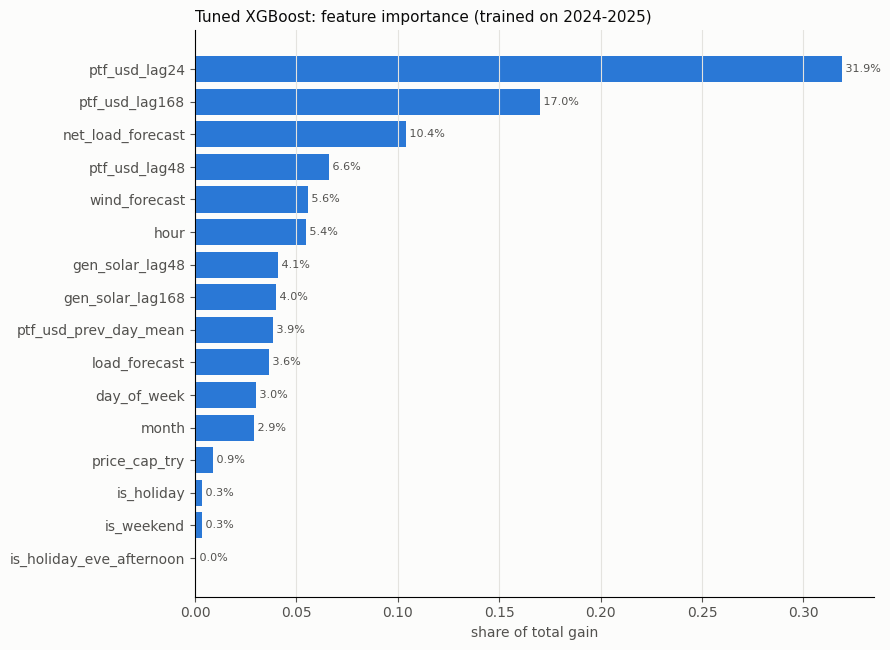

In [13]:
importance = pd.read_csv(RESULTS / 'xgb_feature_importance.csv', index_col='feature')['share']
fig = plots.feature_importance_bars(importance, 'Tuned XGBoost: feature importance (trained on 2024-2025)')

GROUPS = {'past prices': ['ptf_usd_lag24', 'ptf_usd_lag48', 'ptf_usd_lag168', 'ptf_usd_prev_day_mean'],
          'load and wind forecasts': ['load_forecast', 'wind_forecast', 'net_load_forecast'],
          'calendar': ['hour', 'day_of_week', 'is_weekend', 'month', 'is_holiday', 'is_holiday_eve_afternoon'],
          'past solar': ['gen_solar_lag48', 'gen_solar_lag168'],
          'price cap': ['price_cap_try']}
assert sorted(sum(GROUPS.values(), [])) == sorted(importance.index)   # every input in exactly one group
pd.Series({group: importance[cols].sum() for group, cols in GROUPS.items()}, name='share').map('{:.1%}'.format)

**Findings (3.6)**

1. **Past prices carry most of the model (59.4%).** The same hour yesterday alone is 31.9%, the same hour last week 17.0%. This matches the autocorrelation in notebook 01 (24 h: 0.83, 168 h: 0.82).
2. **The next-day forecasts add the new information (19.6%).** The net load forecast is the most used non-price input (10.4%): the demand left after wind is what sets the price.
3. **Calendar 12.1%, past solar 8.1%, price cap 0.9%.** Holidays have a small share (0.3%) because they are rare days, not necessarily because they do not matter on those days.

## 3.7 Test: what did the model do on new data?

The tuned XGBoost was trained on all training data (2024-01-01 – 2025-12-31) and scored **once** on January–September 2026, with the same inputs and metric. No setting was changed after this result.

*Source: `python -m scripts.evaluate_test` → `reports/results/test_scores.csv`, `test_predictions.csv`*

In [14]:
from src.config import TIMEZONE

def read_hourly(path):
    frame = pd.read_csv(path, index_col='time')
    frame.index = pd.to_datetime(frame.index, utc=True).tz_convert(TIMEZONE)
    return frame

test = read_hourly(RESULTS / 'test_predictions.csv')
test_scores = pd.read_csv(RESULTS / 'test_scores.csv', index_col='model')
test_scores[['mae', 'rmse', 'mae_floor_hours', 'mae_cap_hours', 'vs_baseline_%']]

,mae,rmse,mae_floor_hours,mae_cap_hours,vs_baseline_%
model,,,,,
xgboost (tuned),18.57,24.62,24.22,4.20,-51.95
same hour yesterday,12.22,18.55,3.53,8.47,0.00
same hour last week,14.08,21.10,5.51,7.94,-15.16


In [15]:
by_month = pd.read_csv(RESULTS / 'test_scores_by_month.csv', index_col='month')
by_month['model better than baseline'] = by_month['xgboost (tuned)'] < by_month['same hour yesterday']
print(f"model better than the baseline in {by_month['model better than baseline'].sum()} of {len(by_month)} months")
by_month

model better than the baseline in 5 of 9 months


,xgboost (tuned),same hour yesterday,same hour last week,model better than baseline
month,,,,
2026-01,5.95,9.37,8.39,True
2026-02,16.24,17.20,18.60,True
2026-03,19.82,15.16,19.19,False
2026-04,34.88,12.04,14.34,False
2026-05,33.56,7.54,11.01,False
2026-06,27.89,11.71,16.14,False
2026-07,12.07,13.01,15.55,True
2026-08,8.47,11.88,12.97,True
2026-09,8.54,12.57,10.90,True


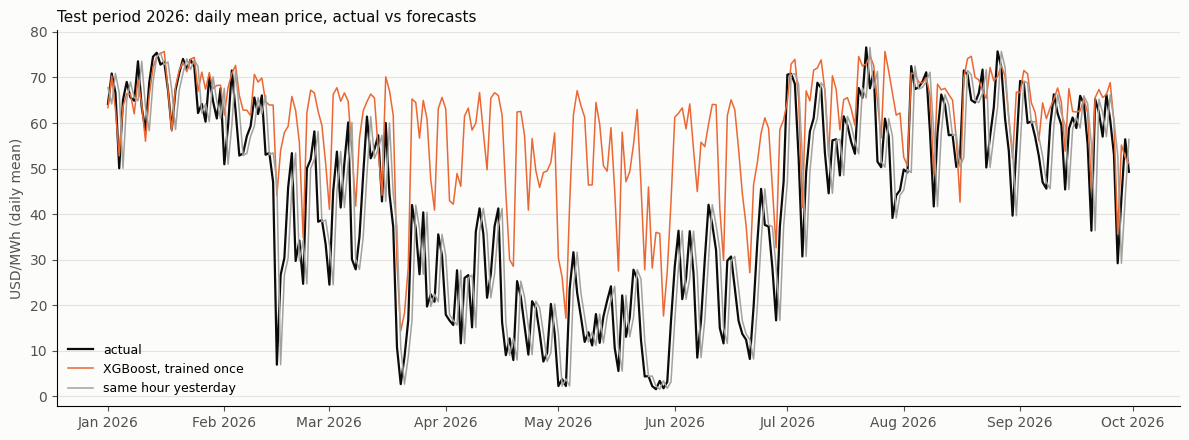

In [16]:
FROZEN, BASELINE = 'xgboost (tuned)', 'same hour yesterday'
fig = plots.daily_forecast_comparison(
    test, {'XGBoost, trained once': (FROZEN, plots.ORANGE), 'same hour yesterday': (BASELINE, plots.GRAY)},
    'Test period 2026: daily mean price, actual vs forecasts')

**What was different in 2026?** Hours at the price floor (PTF = 0), by period:

In [17]:
from src.evaluation import TEST_PERIOD, TRAIN_END, period
from src.features import MODEL_START

floor = table['is_price_floor']
pd.Series({'training, 2024-2025': period(floor, MODEL_START, TRAIN_END).sum(),
           '  of which 2025 (validation)': period(floor, '2025-01-01', TRAIN_END).sum(),
           'test, 2026 Jan-Sep': period(floor, *TEST_PERIOD).sum()}, name='price-floor hours').to_frame()

,price-floor hours
"training, 2024-2025",46
of which 2025 (validation),42
"test, 2026 Jan-Sep",395


**Findings (3.7)**

1. **The model failed on the test period:** MAE 18.57 against 12.22 for the baseline, 52% worse. In validation it had been 32% better.
2. **The failure has a clear time pattern.** The model beat the baseline in 5 of 9 months (January, February, July–September). From March to June it was far worse, at worst in April (34.88 vs 12.04) and May (33.56 vs 7.54).
3. **The test period contained a market situation the training data barely had:** 395 price-floor hours in nine months of 2026, against 46 in the whole of 2024–2025 (42 of them in the validation year). On floor hours the model's error was 24.22, the baseline's 3.53. On price-cap hours the model was better (4.20 vs 8.47).

## 3.8 Why did it fail?

Three questions on the saved test forecasts (nothing is retrained):

1. Is the error **systematic**? Bias = mean of (forecast − actual) by month; above 0 means the forecast was too high.
2. **At which price levels** does the model go wrong?
3. What do the **worst days** have in common?

*Same analysis as `python -m scripts.analyse_errors` (figures in `reports/figures/models/`).*

,xgboost (tuned),same hour yesterday
time,,
2026-01,0.54,0.01
2026-02,14.13,1.22
2026-03,18.00,0.08
2026-04,32.90,0.57
2026-05,32.07,-0.09
2026-06,26.60,-1.02
2026-07,9.02,0.06
2026-08,4.42,-0.29
2026-09,5.05,0.17


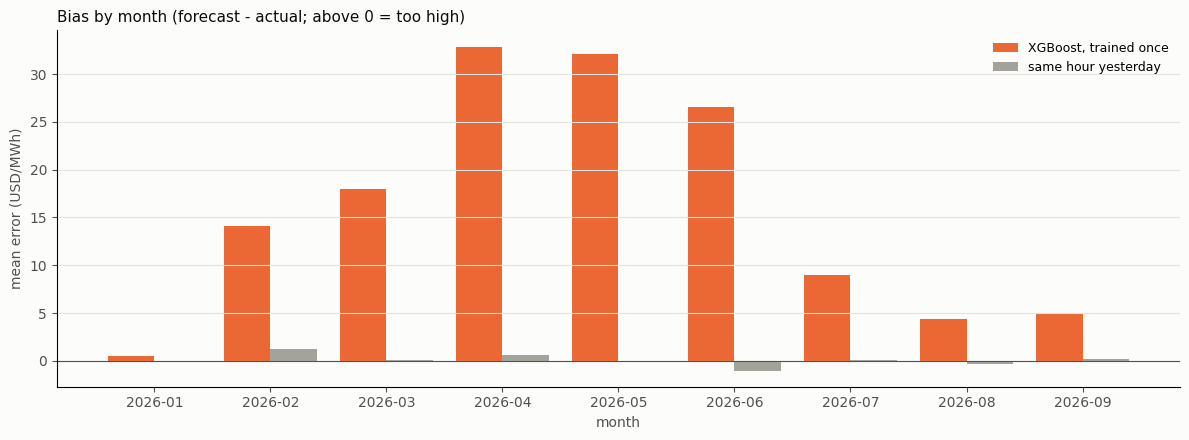

In [18]:
import numpy as np

errors = test[[FROZEN, BASELINE]].sub(test['actual'], axis=0)   # forecast - actual
SHOWN = {'XGBoost, trained once': (FROZEN, plots.ORANGE), 'same hour yesterday': (BASELINE, plots.GRAY)}

bias = errors.groupby(test.index.strftime('%Y-%m')).mean()
fig = plots.grouped_bars(bias, SHOWN, 'Bias by month (forecast - actual; above 0 = too high)', 'month',
                         ylabel='mean error (USD/MWh)')
bias.round(2)

,xgboost (tuned),same hour yesterday,hours
actual,,,
0 (floor),24.24,3.53,397
0-20,37.31,9.76,1522
20-40,24.38,16.65,1110
40-60,14.15,16.56,1007
60-80,5.32,11.01,2078
80+,6.66,13.20,438


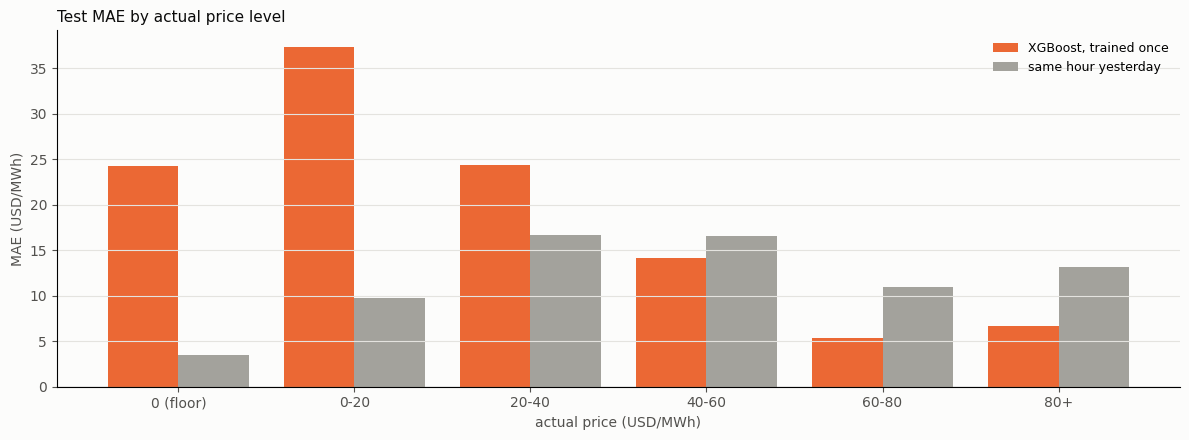

In [19]:
PRICE_BINS = [-0.01, 0.01, 20, 40, 60, 80, np.inf]
PRICE_LABELS = ['0 (floor)', '0-20', '20-40', '40-60', '60-80', '80+']
level = pd.cut(test['actual'], PRICE_BINS, labels=PRICE_LABELS)
by_level = errors.abs().groupby(level, observed=False).mean().assign(hours=level.value_counts())
fig = plots.grouped_bars(by_level, SHOWN, 'Test MAE by actual price level', 'actual price (USD/MWh)')
by_level

In [20]:
daily = errors.abs().groupby(test.index.normalize()).mean()
worst = daily.nlargest(10, FROZEN).assign(actual_mean=test['actual'].resample('D').mean(),
                                          floor_hours=test['is_price_floor'].resample('D').sum())
worst.index = worst.index.strftime('%Y-%m-%d (%a)')
worst

,xgboost (tuned),same hour yesterday,actual_mean,floor_hours
time,,,,
2026-05-08 (Fri),49.38,5.91,11.91,7
2026-05-12 (Tue),48.03,10.00,11.70,7
2026-05-11 (Mon),47.33,10.92,18.03,5
2026-05-07 (Thu),46.75,5.24,17.43,7
2026-04-16 (Thu),45.50,24.99,16.25,1
2026-04-01 (Wed),45.18,14.14,17.90,0
2026-05-06 (Wed),45.11,11.58,22.67,2
2026-04-30 (Thu),44.07,10.62,13.75,6
2026-04-08 (Wed),43.34,13.80,15.10,0


**Findings (3.8)**

1. **The error is systematic, not noise.** From February to June the model forecast too high in every month, by 14–33 USD/MWh on average (April 32.90, May 32.07). The baseline's bias stays within ±1.3 in every month. Even in July–September, when the model beat the baseline again, it was still 4–9 too high.
2. **The failure is specific to low prices.** Below 20 USD/MWh (floor and 0–20, about 1,900 hours) the model's error was 24–37 against 3.5–9.8 for the baseline. In the 60–80 range, the most common price level of the test period (2,078 hours), its error was about half the baseline's (5.32 vs 11.01), and above 80 also about half (6.66 vs 13.20). The model works at the price levels it learned from.
3. **The worst ten days are all in April and May,** with actual daily mean prices of 12–23 USD/MWh, and eight of them had price-floor hours. On those days the model kept forecasting near its usual level.
4. **Interpretation:** in 2024–2025 low prices did not last, so the model had learned that a low price is followed by a higher one. In spring 2026 low prices lasted for weeks, so its error grew. Notebook 01 (section 2.6) shows the supply side of this period: hydro reached 47.5% of generation in April and 49.9% in May. The model has no hydro input.

*Note: 397 test hours have an actual price of exactly 0, while the floor flag marks 395. The 2-hour difference has not been explained; it does not change these results.*

---
# Post-hoc experiments

> ⚠️ Everything below was decided **after** the test result was known. It is not the project's test result (that is 3.7) and it was not used to change the chosen model. Every variant that was tried is reported.

## 3.9 Post-hoc: how often must the model be retrained?

In 3.7 the model was trained once on 2024–2025 and frozen for nine months, while the market changed. A model in daily use would be retrained regularly. Same inputs, same tuned settings, no new tuning; only the update frequency changes. Before each period, the model is trained on all data up to the day before that period:

- **monthly:** retrained on the first day of every month
- **weekly:** retrained every Monday

*Source: `python -m scripts.posthoc_retrain --every month` / `--every week` → `reports/results/posthoc/`*

In [21]:
POSTHOC = RESULTS / 'posthoc'
monthly = pd.read_csv(POSTHOC / 'monthly_retrain_scores.csv', index_col='model')
weekly = pd.read_csv(POSTHOC / 'weekly_retrain_scores.csv', index_col='model')
retrain = pd.concat([weekly.loc[['xgboost (frozen, reported)']], monthly.loc[['xgboost (monthly retrain, post-hoc)']],
                     weekly.loc[['xgboost (weekly retrain, post-hoc)', 'same hour yesterday']]])
retrain[['mae', 'rmse', 'mae_floor_hours', 'mae_cap_hours', 'vs_baseline_%']]

,mae,rmse,mae_floor_hours,mae_cap_hours,vs_baseline_%
model,,,,,
"xgboost (frozen, reported)",18.57,24.62,24.22,4.20,-51.95
"xgboost (monthly retrain, post-hoc)",10.89,15.17,7.75,4.67,10.91
"xgboost (weekly retrain, post-hoc)",9.64,13.83,4.48,4.77,21.15
same hour yesterday,12.22,18.55,3.53,8.47,0.00


In [22]:
retrain_months = pd.read_csv(POSTHOC / 'weekly_retrain_by_month.csv', index_col='month')
retrain_months = retrain_months[['xgboost (frozen, reported)', 'xgboost (monthly retrain, post-hoc)',
                                 'xgboost (weekly retrain, post-hoc)', 'same hour yesterday']]
beats = retrain_months.drop(columns='same hour yesterday').lt(retrain_months['same hour yesterday'], axis=0)
print('months better than the baseline:', beats.sum().to_dict())
retrain_months

months better than the baseline: {'xgboost (frozen, reported)': 5, 'xgboost (monthly retrain, post-hoc)': 7, 'xgboost (weekly retrain, post-hoc)': 9}


,"xgboost (frozen, reported)","xgboost (monthly retrain, post-hoc)","xgboost (weekly retrain, post-hoc)",same hour yesterday
month,,,,
2026-01,5.95,5.95,5.86,9.37
2026-02,16.24,16.36,14.24,17.20
2026-03,19.82,14.05,12.62,15.16
2026-04,34.88,18.58,11.55,12.04
2026-05,33.56,8.06,7.50,7.54
2026-06,27.89,10.77,10.25,11.71
2026-07,12.07,9.36,9.64,13.01
2026-08,8.47,8.03,7.98,11.88
2026-09,8.54,7.51,7.57,12.57


**Findings (3.9)**

1. **The same model, retrained weekly, beat the baseline by 21% (MAE 9.64 vs 12.22) and in all nine months.** Monthly retraining gave 10.89 (11% better, 7 of 9 months); trained once, 18.57 (5 of 9).
2. **Retraining fixed the low-price weakness:** MAE on price-floor hours fell from 24.22 (trained once) to 4.48 (weekly), close to the baseline's 3.53.
3. **The hardest months stayed close:** under weekly retraining, April and May were only marginally better than the baseline (11.55 vs 12.04, 7.50 vs 7.54).
4. **Conclusion:** the model was not wrong, it was out of date. A price model like this has to be retrained at least weekly; a single training run is not enough when the market changes.

## 3.10 Post-hoc: classical time series models

Added after the test, to compare more of the methods covered in the bootcamp (`src/timeseries.py`). They forecast the price series from its own past; SARIMAX and Prophet also use the next-day net load forecast. Like every other model here, they forecast D+1 from data known on day D, and receive D+1's prices only after the forecast.

- **Holt-Winters** (exponential smoothing, additive daily or weekly season): each day the forecast is updated with the latest prices.
- **SARIMAX** with a daily (24-hour) season: estimated on the last 8 weeks before the forecast period, because its memory use grows with the length of the series; each day its state is updated with the latest prices.
- **Prophet** (daily and weekly season, official holidays): refitted every day, because it has no cheap way to add new data.

Candidates were compared on the same 2025 quarters; the best of each family was then scored on the test period under the two protocols of 3.9 (trained once / retrained weekly).

*Sources: `python -m scripts.evaluate_timeseries` → `timeseries_walk_forward.csv`; `python -m scripts.evaluate_timeseries_test` → `posthoc/timeseries_test_*`*

In [23]:
timeseries = pd.read_csv(RESULTS / 'timeseries_walk_forward.csv')
mean_over_folds(pd.concat([timeseries, reference, baseline]))

fold,2025Q1,2025Q2,2025Q3,2025Q4,mean,vs_baseline_%
model,,,,,,
xgboost (tuned),6.76,9.03,5.15,6.60,6.88,32.12
"sarimax (1,0,1)(1,0,1,24)",8.10,12.46,8.52,7.40,9.12,10.06
"sarimax (1,0,1)(0,1,1,24)",7.56,11.94,11.16,7.74,9.60,5.34
"prophet, yearly season",8.49,14.02,8.57,8.90,10.00,1.41
same hour yesterday,8.66,14.20,9.12,8.58,10.14,0.00
prophet,8.57,14.12,8.77,9.75,10.30,-1.58
"holt-winters, 24h season",11.76,13.64,12.87,12.69,12.74,-25.64
"holt-winters, 168h season",13.71,18.60,10.48,15.08,14.47,-42.70


In [24]:
ts_test = pd.read_csv(POSTHOC / 'timeseries_test_scores.csv', index_col='model')
ts_test[['mae', 'rmse', 'mae_floor_hours', 'vs_baseline_%']].sort_values('mae')

,mae,rmse,mae_floor_hours,vs_baseline_%
model,,,,
xgboost (weekly),9.64,13.83,4.48,21.15
"sarimax (1,0,1)(1,0,1,24) (weekly)",10.80,14.62,11.03,11.64
same hour yesterday,12.22,18.55,3.53,0.00
"prophet, yearly season (re-fitted daily)",13.48,17.74,12.28,-10.26
"sarimax (1,0,1)(1,0,1,24) (once)",15.08,19.09,25.59,-23.40
"holt-winters, 24h season (weekly)",16.03,20.69,20.53,-31.12
"holt-winters, 24h season (once)",16.04,20.74,22.02,-31.23
"xgboost (once, reported)",18.57,24.62,24.22,-51.95


In [25]:
ts_months = pd.read_csv(POSTHOC / 'timeseries_test_by_month.csv', index_col='month')
ts_months[['xgboost (weekly)', 'sarimax (1,0,1)(1,0,1,24) (weekly)', 'same hour yesterday']]

,xgboost (weekly),"sarimax (1,0,1)(1,0,1,24) (weekly)",same hour yesterday
month,,,
2026-01,5.86,7.68,9.37
2026-02,14.24,13.07,17.20
2026-03,12.62,13.49,15.16
2026-04,11.55,13.22,12.04
2026-05,7.50,11.39,7.54
2026-06,10.25,12.11,11.71
2026-07,9.64,10.29,13.01
2026-08,7.98,7.72,11.88
2026-09,7.57,8.48,12.57


**Findings (3.10)**

1. **Validation: SARIMAX is the best classical model (9.12, 10% better than the baseline),** Prophet is about level with the baseline (10.00 with a yearly season), Holt-Winters is worse (12.74). All of them stay far behind the tuned XGBoost (6.88).
2. **The test ranking is the same as in validation:** XGBoost, then SARIMAX, then the baseline, then Prophet and Holt-Winters. Retrained weekly, SARIMAX was 12% better than the baseline (10.80) and better than weekly XGBoost in February (13.07 vs 14.24) and August (7.72 vs 7.98).
3. **Trained once, every classical model was better than the frozen XGBoost** (SARIMAX 15.08, Holt-Winters 16.04 vs 18.57), because each one updates its forecast with the latest prices every day. None of them beat the baseline that way. Retraining Holt-Winters weekly did not help (16.03).
4. **Why the gap to XGBoost** (interpretation, not tested separately): the classical models see fewer inputs (Holt-Winters only past prices, SARIMAX and Prophet one external input against 16), and SARIMAX and Holt-Winters are linear with a fixed seasonal pattern, while the price has thresholds (floor, cap, a jump when expensive plants are needed) that tree models learn on their own.

### 3.10b Post-hoc: information or model?

XGBoost sees 16 inputs, the classical models one or none. Is XGBoost better because it **knows more**, or because it is a **better model**? Both kinds of model get the same information (2025 validation):

- **own past only:** SARIMA without external inputs vs XGBoost with past prices and the hour only
- **all inputs:** SARIMAX with every input of XGBoost vs the tuned XGBoost of 3.4

Thresholds set before the run: time series count as competitive below 7.38; "the gap is mostly information" if XGBoost with past prices only is above 8.6.

*Source: `python -m scripts.information_vs_model` → `posthoc/information_vs_model.csv`*

In [26]:
info = pd.read_csv(POSTHOC / 'information_vs_model.csv')
mean_over_folds(pd.concat([info, reference, baseline]))

fold,2025Q1,2025Q2,2025Q3,2025Q4,mean,vs_baseline_%
model,,,,,,
xgboost (tuned),6.76,9.03,5.15,6.60,6.88,32.12
"xgboost, own past only",7.31,12.38,6.49,7.17,8.34,17.78
"sarimax, all inputs",7.30,12.71,10.42,8.04,9.62,5.17
"sarima, own past only",7.57,13.90,10.07,8.03,9.89,2.45
"sarimax, all inputs (maxiter 200)",7.29,13.00,11.63,8.08,10.00,1.39
same hour yesterday,8.66,14.20,9.12,8.58,10.14,0.00


**Findings (3.10b)**

1. **With the same information XGBoost is still clearly better:** with past prices and the hour only it reaches 8.34, better than every time series model and better than ridge with all inputs (8.97, section 3.3).
2. **The extra inputs did not help SARIMAX:** 10.00 with all inputs (converged with 200 iterations; 9.62 with the default 50, not converged), worse than with the net load forecast alone (9.12). A linear model with a fixed pattern cannot use thresholds such as the floor and the cap.
3. Neither threshold was reached: **the gap comes mainly from the model, not the information.** XGBoost kept its tuned settings with fewer inputs, which slightly favours the full model.

## 3.11 Post-hoc addition: what is the forecast worth for a decision?

The project forecasts prices; this section only illustrates one use of those forecasts (`src/business.py`).

A consumer has a flexible job that needs 4 (or 8) hours of 1 MW every day, in any hours. On day D it runs the job in the hours of D+1 that the forecast says are cheapest, and pays the **actual** prices of those hours. Two references:

- **no shifting:** the day's average actual price
- **perfect foresight:** the truly cheapest hours

*Captured share* = (no shifting − forecast) / (no shifting − perfect foresight): 100% is as good as knowing tomorrow's prices, 0% is no better than not shifting. Only the order of the forecast prices within a day matters here, not their level.

*Source: `python -m scripts.evaluate_load_shifting` → `reports/results/business/`*

In [27]:
shifting = pd.read_csv(RESULTS / 'business' / 'load_shifting.csv')
shifting.query('n_hours == 4').set_index('forecast').drop(columns='n_hours')

,price_no_shifting,price_perfect,price_forecast,saving_per_mwh,captured_%,days_worse_than_no_shifting,days
forecast,,,,,,,
"xgboost (once, reported)",43.09,20.98,24.25,18.83,85.20,3,273
same hour yesterday,43.09,20.98,27.14,15.94,72.13,13,273
same hour last week,43.09,20.98,26.01,17.08,77.26,8,273
"xgboost (weekly, post-hoc)",43.09,20.98,24.32,18.77,84.91,2,273
"sarimax (weekly, post-hoc)",43.09,20.98,25.83,17.26,78.07,13,273


In [28]:
shifting.pivot(index='forecast', columns='n_hours', values='captured_%').add_prefix('captured %, hours = ')

n_hours,"captured %, hours = 4","captured %, hours = 8"
forecast,,
same hour last week,77.26,78.45
same hour yesterday,72.13,72.02
"sarimax (weekly, post-hoc)",78.07,79.45
"xgboost (once, reported)",85.20,85.01
"xgboost (weekly, post-hoc)",84.91,86.01


**Findings (3.11)**

1. **With 4 flexible hours, following the frozen model paid 24.25 USD/MWh on average,** against 43.09 without shifting and 20.98 with perfect foresight: 85% of the possible saving. The same hour yesterday captured 72%.
2. **The model that failed on MAE (3.7) did well on this decision.** In spring it forecast every hour too high (3.8), but it still ranked the hours of a day well, and only the ranking matters for choosing hours. Weekly retraining (85%) did not improve it further.
3. This does not change the main result: as a **price** forecast, the frozen model failed on the test period.

---
## 3.12 Round 2: temperature, hydro and a new split

> Started **after** the round-1 test and a project review (why no temperature, why not beat the simple baselines, shouldn't time series models do better). Sections 3.1–3.11 stay as they were. Round 2 has its own split and its own one-time test.

| | Round 1 (3.1–3.11) | Round 2 |
|---|---|---|
| Inputs | 16 (`v1`) | 21 (`v2`): + temperature forecast, heating and cooling degrees (below / above 18 °C), hydro share of generation and its 7-day mean |
| Validation | 2025, 4 quarters | 2025Q1–2026Q3, 7 quarters (the round-1 test becomes validation) |
| Test | 2026-01-01 – 2026-09-30 | 2026-10-01 – 2026-11-01 |
| New model | – | LEAR (lasso per delivery hour, 247 inputs; `src/lear.py`) |

- **Temperature** is a forecast, not a measurement: the equal-weight mean of five cities from the Open-Meteo Historical Forecast API (`src/weather.py`).
- **Hydro** was chosen from the error analysis (3.8): its 7-day share of generation was 0.47–0.49 in spring 2026, at most 0.36 before.

Like every input, the new ones pass the leakage check (3.1): temperature is known ahead (lag 0), hydro share is realised generation (lag ≥ 48 hours).

In [29]:
from src.features import FEATURE_SETS, build_features

ROUND2 = RESULTS / 'round2'
X2, y2 = build_features(table, FEATURE_SETS['v2'])
print(len(X2.columns), 'inputs; new in v2:', [c for c in X2.columns if c.startswith(('temperature', 'hydro'))])


def mean_over_quarters(results: pd.DataFrame) -> pd.DataFrame:
    # MAE per quarter, mean over the 7 quarters, and the 2025 / 2026 means
    per_fold = results.pivot_table(index='model', columns='fold', values='mae')
    folds = list(per_fold.columns)
    per_fold['mean'] = per_fold[folds].mean(axis=1)
    per_fold['mean 2025'] = per_fold[[f for f in folds if f.startswith('2025')]].mean(axis=1)
    per_fold['mean 2026'] = per_fold[[f for f in folds if f.startswith('2026')]].mean(axis=1)
    return per_fold.sort_values('mean')

21 inputs; new in v2: ['temperature_forecast', 'temperature_heating', 'temperature_cooling', 'hydro_share_lag48', 'hydro_share_7d_lag48']


### Step 1: every model with v1 and v2 inputs, trained once per quarter

*Source: `python -m scripts.round2_compare` → `round2/comparison.csv`*

In [30]:
compare = pd.read_csv(ROUND2 / 'comparison.csv')
compare['model'] = compare['model'] + ' [' + compare['inputs'] + ']'
mean_over_quarters(compare)

fold,2025Q1,2025Q2,2025Q3,2025Q4,2026Q1,2026Q2,2026Q3,mean,mean 2025,mean 2026
model,,,,,,,,,,
xgboost (round-1 tuned settings) [v2],6.96,9.14,5.24,6.56,15.11,14.81,8.39,9.46,6.98,12.77
random forest [v2],6.76,9.71,6.24,6.36,13.72,15.23,9.27,9.61,7.27,12.74
xgboost (round-1 tuned settings) [v1],6.76,9.03,5.15,6.60,13.93,17.83,8.74,9.72,6.88,13.50
random forest [v1],6.77,9.82,6.08,6.43,13.10,16.49,9.39,9.73,7.27,12.99
hist gradient boosting [v2],7.57,9.20,5.52,6.37,14.40,17.01,8.49,9.79,7.17,13.30
xgboost [v2],7.71,9.14,5.70,6.86,15.66,17.15,8.54,10.11,7.35,13.78
lear [v1],6.13,10.40,5.76,6.34,12.44,24.07,8.21,10.48,7.16,14.91
lear [v2],6.09,10.77,5.75,6.22,12.27,24.92,8.15,10.60,7.21,15.12
xgboost [v1],7.02,9.33,5.50,6.93,14.18,20.19,11.45,10.66,7.19,15.27


### Step 2: tuning (Optuna) on the 7 quarters, v2 inputs

*Source: `python -m scripts.tune_models --round 2` → `round2/tuning/`*

In [31]:
tuned2 = pd.read_csv(ROUND2 / 'tuning' / 'tuned_comparison.csv')
untuned2 = pd.read_csv(ROUND2 / 'comparison.csv').query("inputs == 'v2' or model == 'same hour yesterday'")
untuned2 = untuned2[untuned2['model'].isin(['xgboost', 'random forest', 'hist gradient boosting', 'same hour yesterday'])]
mean_over_quarters(pd.concat([untuned2, tuned2]))

fold,2025Q1,2025Q2,2025Q3,2025Q4,2026Q1,2026Q2,2026Q3,mean,mean 2025,mean 2026
model,,,,,,,,,,
hist gradient boosting (tuned),7.23,8.95,5.17,6.51,14.79,12.88,8.66,9.17,6.97,12.11
xgboost (tuned),6.97,9.19,5.25,6.47,15.22,13.92,8.56,9.37,6.97,12.57
random forest (tuned),6.63,9.68,6.10,6.33,13.66,15.67,9.06,9.59,7.18,12.80
random forest,6.76,9.71,6.24,6.36,13.72,15.23,9.27,9.61,7.27,12.74
hist gradient boosting,7.57,9.20,5.52,6.37,14.40,17.01,8.49,9.79,7.17,13.30
xgboost,7.71,9.14,5.70,6.86,15.66,17.15,8.54,10.11,7.35,13.78
same hour yesterday,8.66,14.20,9.12,8.58,13.80,10.40,12.49,11.03,10.14,12.23


### Step 3: final choice with weekly retraining

Round 1 showed (3.9) that the model must be retrained at least weekly. So the candidates are retrained every Monday on all data up to the day before, over all 7 quarters (92 weekly models each). **Rule set before the run:** the lowest mean over the 7 quarters is chosen.

*Source: `python -m scripts.round2_weekly` → `round2/weekly_selection.csv`*

In [32]:
weekly2 = mean_over_quarters(pd.read_csv(ROUND2 / 'weekly_selection.csv'))
weekly2['quarters better than baseline'] = (
    weekly2.filter(like='Q').lt(weekly2.loc['same hour yesterday'].filter(like='Q'), axis=1).sum(axis=1))
weekly2

fold,2025Q1,2025Q2,2025Q3,2025Q4,2026Q1,2026Q2,2026Q3,mean,mean 2025,mean 2026,quarters better than baseline
model,,,,,,,,,,,
"hist gradient boosting (tuned, v2)",6.47,8.83,4.92,5.92,10.52,9.07,8.38,7.73,6.53,9.32,7
"xgboost (tuned, v2)",6.28,8.85,4.97,5.97,11.12,9.31,8.39,7.84,6.52,9.61,7
"random forest (tuned, v2)",6.46,9.41,5.64,6.12,11.18,9.78,8.56,8.16,6.91,9.84,7
lear (v1),5.86,9.67,5.48,6.09,11.30,19.96,7.97,9.47,6.77,13.08,6
same hour yesterday,8.66,14.20,9.12,8.58,13.80,10.40,12.49,11.03,10.14,12.23,0


### Step 4: which inputs matter?

Two checks on the chosen model (validation only):

- **Ablation:** drop a group of inputs and retrain weekly. Answers "would we miss these inputs?".
- **Permutation:** in a quarter the model was not trained on, shuffle one input and measure how much the MAE rises. Answers "how much does the model rely on it?". Inputs that carry the same information (the three temperature columns) are also shuffled as a group; one at a time, each would look unimportant because the model takes the information from the others.

Expectation written before the run: hydro matters more than temperature, mainly in 2026Q1–Q2.

*Source: `python -m scripts.round2_importance` → `round2/ablation.csv`, `round2/permutation.csv`*

In [33]:
pd.read_csv(ROUND2 / 'ablation.csv', index_col='inputs')

,2025Q1,2025Q2,2025Q3,2025Q4,2026Q1,2026Q2,2026Q3,mean,mean 2025,mean 2026
inputs,,,,,,,,,,
all v2 inputs,6.47,8.83,4.92,5.92,10.52,9.07,8.38,7.73,6.53,9.32
without temperature,6.63,8.88,4.88,6.05,10.78,9.29,8.57,7.87,6.61,9.55
without hydro,6.43,8.82,4.87,5.79,10.40,9.62,8.43,7.76,6.48,9.48
without both (= v1),6.60,8.86,4.92,5.84,10.40,9.58,8.48,7.81,6.55,9.49


In [34]:
permutation = pd.read_csv(ROUND2 / 'permutation.csv', index_col='input')
permutation[['mean', 'mean 2025', 'mean 2026', '2026Q1', '2026Q2']].head(10)

,mean,mean 2025,mean 2026,2026Q1,2026Q2
input,,,,,
ptf_usd_lag24,2.55,1.81,3.55,2.13,5.56
net_load_forecast,2.33,2.92,1.55,2.45,0.57
ptf_usd_lag168,1.25,0.86,1.77,1.09,1.94
gen_solar_lag48,0.78,1.06,0.41,-0.02,0.08
gen_solar_lag168,0.65,0.90,0.31,0.17,0.23
hour,0.59,0.56,0.62,0.28,1.14
day_of_week,0.56,0.55,0.56,0.17,0.52
wind_forecast,0.55,0.48,0.65,0.24,0.81
ptf_usd_lag48,0.35,0.20,0.55,0.45,0.88


In [35]:
permutation.loc[[i for i in permutation.index if 'temperature' in i or 'hydro' in i],
                ['mean', 'mean 2025', 'mean 2026', '2026Q1', '2026Q2']].round(2)

,mean,mean 2025,mean 2026,2026Q1,2026Q2
input,,,,,
[group] temperature,0.13,0.14,0.13,0.18,0.18
temperature_forecast,0.10,0.10,0.09,0.12,0.14
temperature_heating,0.02,0.02,0.02,0.03,0.03
[group] hydro,0.01,-0.00,0.02,-0.21,0.31
hydro_share_7d_lag48,0.00,-0.01,0.02,-0.22,0.28
temperature_cooling,-0.00,-0.00,-0.00,-0.00,-0.00
hydro_share_lag48,-0.01,0.01,-0.03,-0.09,0.05


### Step 5: test, 2026-10-01 – 2026-11-01, scored once

The test ends on the last day with every input available (the weather archive lags about two days). October 2026 had already been shown in the round-1 demo, with a different model; no round-2 choice used it.

*Source: `python -m scripts.round2_test` → `round2/test_scores.csv`, `round2/test_scores_by_week.csv`*

In [36]:
test2 = pd.read_csv(ROUND2 / 'test_scores.csv', index_col='model')
test2['vs_baseline_%'] = 100 * (1 - test2['mae'] / test2.loc['same hour yesterday', 'mae'])
test2[['mae', 'rmse', 'mae_floor_hours', 'floor_hours', 'vs_baseline_%']]

,mae,rmse,mae_floor_hours,floor_hours,vs_baseline_%
model,,,,,
hist gradient boosting (chosen),7.74,10.58,7.58,18.0,31.88
xgboost (context),7.62,10.40,8.69,18.0,33.00
same hour yesterday,11.37,17.71,29.45,18.0,0.00
same hour last week,15.02,19.40,1.26,18.0,-32.16


In [37]:
pd.read_csv(ROUND2 / 'test_scores_by_week.csv', index_col='week from')

,hist gradient boosting (chosen),xgboost (context),same hour yesterday,same hour last week
week from,,,,
2026-09-28,8.55,8.37,10.93,17.20
2026-10-05,7.37,7.45,11.08,16.65
2026-10-12,8.42,8.17,13.82,15.34
2026-10-19,7.26,7.45,10.25,14.71
2026-10-26,7.46,6.96,10.57,12.14


### Is "same hour yesterday" a fair bar?

It forecasts a Saturday from a Friday and a Monday from a Sunday. A natural alternative keeps the day type, for example the same day last year. The model is compared with four simple forecasts: yesterday, last week, the same weekday last year (52 weeks earlier) and a weekday-aware rule (last week on Sundays and Mondays, yesterday otherwise; built from the validation table).

*Source: `python -m scripts.round2_baselines` → `round2/baselines_overall.csv`, `round2/baselines_by_weekday.csv`*

In [38]:
pd.read_csv(ROUND2 / 'baselines_overall.csv', index_col='forecast')

,validation 2025Q1-2026Q3,test Oct 2026
forecast,,
model (weekly retrained),7.72,7.74
same hour yesterday,11.03,11.37
same hour last week,11.90,15.02
same weekday last year,18.59,13.93
weekday-aware (last week on Sun/Mon),9.78,9.40


In [39]:
pd.read_csv(ROUND2 / 'baselines_by_weekday.csv', index_col=['period', 'weekday']).loc['validation']

,model (weekly retrained),same hour yesterday,same hour last week,same weekday last year,weekday-aware (last week on Sun/Mon)
weekday,,,,,
Mon,8.41,18.98,12.25,19.29,12.25
Tue,7.20,9.53,11.82,17.51,9.53
Wed,7.67,8.78,11.03,17.63,8.78
Thu,7.34,8.60,12.22,18.33,8.60
Fri,7.16,7.60,12.45,19.17,7.60
Sat,7.66,10.26,12.10,19.01,10.26
Sun,8.61,13.49,11.44,19.23,11.44


**Findings (3.12)**

1. **Trained once per quarter, no model beat the baseline on its 2026 mean, and none came close in 2026Q2** (baseline 10.40, best model 13.54). New inputs and tuning helped (XGBoost round-1 settings: 9.72 → 9.46 with v2; HistGradientBoosting 9.79 → 9.17 tuned), but not enough.
2. **Retrained weekly, the chosen tuned HistGradientBoosting reached 7.73 and beat the baseline in all 7 quarters**, including 2026Q1 (10.52 vs 13.80) and 2026Q2 (9.07 vs 10.40). XGBoost is practically equal (7.84); the pre-set rule decided.
3. **Temperature and hydro add little:** all v2 inputs 7.73, without both (= v1) 7.81. **The expectation was wrong:** temperature helped a little in 6 of 7 quarters (7.87 without it), hydro only in 2026Q2. The model relies mostly on yesterday's price and the net load forecast. A likely reason (not tested directly): EPİAŞ's load forecast already depends on the weather. Differences of about 0.1 are close to noise.
4. **LEAR**, the literature's lasso model, was close to the tree models in 2025 (7.16 trained once) but failed again in 2026Q2 (19.96 even with weekly retraining).
5. **Test: 7.74 vs 11.37 for the baseline (32% better),** better in all 5 weeks and on 24 of 32 days (if both forecasts were equally good, a record this good would happen by chance with a probability of about 0.35%, one-sided sign test); the validation estimate (7.73) held. **What fixed the dummy / baseline problem was the retraining frequency, not the new inputs.**
6. **The bar is fair, and the model beats stronger ones too.** Same hour yesterday is worst exactly when the day type changes (validation: Monday 18.98, Sunday 13.49). Same weekday last year is worse still (18.59 on validation), because the price level moved too much in a year. The strongest simple rule (last week on Sundays and Mondays, yesterday otherwise) reaches 9.40 on the test, against 7.74 for the model (18% better, better on 23 of 32 days).

## 3.13 Round 2 business layer: should a power plant prepare to run tomorrow?

Load shifting (3.11) only needs the **order** of tomorrow's hours. A power plant also needs the **level**: is tomorrow's price above my cost?

**Which decision?** Hour by hour, the day-ahead auction decides by itself: an hourly offer at the plant's cost is accepted only when the price is higher, so no forecast is needed for that. What the auction cannot decide is what must be fixed on day D, **before** the prices are known: which block of hours to offer, how much gas to nominate, whether to staff and prepare a start-up.

**Simulation** (`src/plant.py`), a simplified unit commitment of a 1 MW gas plant with variable cost X USD/MWh:

- at most one block of consecutive hours per day, at least 4 hours; each start costs 50 USD
- the block with the largest sum of (forecast − X) is chosen; if it does not cover the start cost, the plant stays off
- profit uses the **actual** prices of the hours run
- references: perfect foresight (the best block by actual prices) and always run

X is swept from 20 to 90 USD/MWh, because the plant's cost is not known. The start cost and the minimum run are also assumptions, checked with other values.

Expectation written before the run: the model captures more than the baseline at every cost, most where X is near the typical price (50–70).

*Source: `python -m scripts.evaluate_plant` → `round2/business/`*

In [40]:
plant = pd.read_csv(ROUND2 / 'business' / 'plant_by_cost.csv')
profit = plant.pivot(index='cost', columns='source', values='profit')
profit['model - baseline'] = profit['model'] - profit['same hour yesterday']
profit.round(0)

source,always run,model,perfect foresight,same hour yesterday,model - baseline
cost,,,,,
20,28546.0,28591.0,28593.0,28164.0,428.0
25,24706.0,24832.0,24861.0,24534.0,298.0
30,20866.0,21098.0,21252.0,20449.0,649.0
35,17026.0,17406.0,17680.0,16392.0,1014.0
40,13186.0,13802.0,14272.0,12494.0,1308.0
45,9346.0,10744.0,11076.0,9602.0,1141.0
50,5506.0,7535.0,8064.0,6539.0,996.0
55,1666.0,4939.0,5439.0,4141.0,798.0
60,-2174.0,2477.0,3410.0,2071.0,406.0


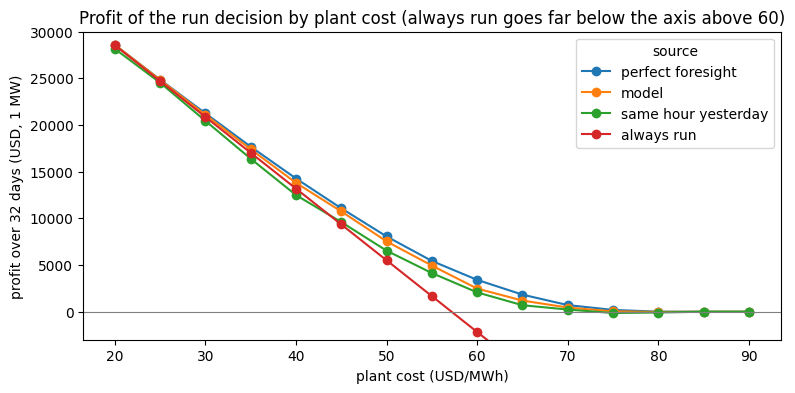

In [41]:
ax = profit[['perfect foresight', 'model', 'same hour yesterday', 'always run']].plot(marker='o', figsize=(9, 4))
ax.set(ylim=(-3000, 30000), xlabel='plant cost (USD/MWh)', ylabel='profit over 32 days (USD, 1 MW)',
       title='Profit of the run decision by plant cost (always run goes far below the axis above 60)')
ax.axhline(0, color='grey', linewidth=0.8);

In [42]:
sensitivity = pd.read_csv(ROUND2 / 'business' / 'plant_sensitivity.csv')
check = sensitivity.pivot_table(index=['min_hours', 'start_cost', 'cost'], columns='source', values='profit')
check['model - baseline'] = check['model'] - check['same hour yesterday']
check[['perfect foresight', 'model', 'same hour yesterday', 'model - baseline']].round(0)

source                     perfect foresight    model  same hour yesterday  model - baseline
min_hours start_cost cost                                                                   
4         0.0        40              15872.0  15553.0              14094.0            1458.0
                     55               7000.0   6449.0               5799.0             650.0
                     65               3325.0   2648.0               2222.0             426.0
                     75               1290.0   1062.0                949.0             113.0
          50.0       40              14272.0  13802.0              12494.0            1308.0
                     55               5439.0   4939.0               4141.0             798.0
                     65               1829.0   1195.0                694.0             501.0
                     75                193.0     42.0               -138.0             180.0
          150.0      40              11133.0  10766.0               9484.0            1282.0
                     55               2593.0   2213.0               1298.0             915.0
                     65                156.0   -214.0               -691.0             477.0
                     75                  0.0      0.0                  0.0               0.0
8         50.0       40              14236.0  13803.0              12527.0            1276.0
                     55               5370.0   4889.0               4203.0             686.0
                     65               1719.0   1077.0                618.0             459.0
                     75                108.0    -89.0               -125.0              36.0

**Findings (3.13)**

1. **The model earned more than the baseline at every cost from 20 to 80 USD/MWh** (60–1,300 USD per MW over 32 days), and in 15 of 16 sensitivity cases (in the 16th all forecasts kept the plant off).
2. **The expectation was only partly right:** in USD the gap was largest at 40–50, below the median price (61.8), where the plant runs many hours and many hours are at stake.
3. **A forecast matters where the decision is close:** a cheap plant (20) gets 99.8% of perfect by always running; at 60, always running loses 2,174 USD while the model earns 2,477.
4. **The gain comes from a few unusual days:** at a cost of 50, model and baseline decided the same on 15 of 32 days, the model was better on 12 and worse on 5. On Sunday 11 October midday prices fell to 0. The baseline copied Saturday and ran all day (−146 USD). The model ran the evening block (+105; perfect 113).
5. **Limits:** one block per day, the plant does not move the price, one month, assumed costs. It is a comparison of forecasts under the same rules, not a plant's real profit.

---
## Summary

| Question | Answer | Evidence |
|---|---|---|
| Inputs | 16, all known before 12:30 on day D; leakage is blocked in code | 3.1 |
| Bar to beat | same hour yesterday, MAE 10.14 (validation) | 3.2 |
| Model family | tree ensembles (28–30% better than the baseline with starting settings) | 3.3 |
| Chosen model | tuned XGBoost, MAE 6.88 (32% better than the baseline) | 3.4 |
| Deep learning | GRU 8.61 at best; pre-set bars missed, not tested | 3.5 |
| What the model uses | past prices 59%, load and wind forecasts 20%, calendar 12% | 3.6 |
| **Test result** | **MAE 18.57 vs 12.22: failed (52% worse than the baseline)** | 3.7 |
| Why | a long low-price period (395 floor hours vs 46 in training); forecasts too high by 14–33 USD/MWh per month, February–June | 3.8 |
| *Post-hoc:* retraining | weekly retraining: 9.64, 21% better than the baseline, 9 of 9 months | 3.9 |
| *Post-hoc:* classical models | best is weekly SARIMAX, 10.80; same ranking as in validation | 3.10 |
| *Post-hoc:* information or model | with the same information XGBoost is still better (8.34 vs 9.89 on past prices only) | 3.10b |
| *Post-hoc:* use for a decision | choosing the 4 cheapest hours: 85% of the possible saving (baseline 72%) | 3.11 |
| **Round 2:** final model | tuned HistGradientBoosting, 21 inputs, retrained every Monday: validation 7.73 (7 of 7 quarters better than the baseline) | 3.12 |
| **Round 2:** temperature, hydro | small gain (7.81 → 7.73); the model relies on yesterday's price and the net load forecast | 3.12 |
| **Round 2: test** | **MAE 7.74 vs 11.37 (32% better), October 2026** | 3.12 |
| **Round 2:** use for a decision | a plant's pre-auction run decision: more profit than the baseline at every cost (up to +1,308 USD per MW in 32 days) | 3.13 |

**Limitations**

- The round-1 validation year had only 42 price-floor hours, so it could not reveal the weakness at long low-price periods.
- The temperature input is an archive of forecasts stitched from the first hours of each run, so it is somewhat more accurate than a forecast made the day before; the five cities have equal weight. Hydro enters only as its share of past generation, not as reservoir levels.
- Everything in 3.9–3.11 was decided after the round-1 test result was known; round 2 (3.12) has its own split and test, but was also started after it. Its test covers one month.
- The 8-week estimation window of SARIMAX was set by memory limits, not chosen on validation.